## Lab - EDA Univariate Analysis: Diving into Amazon UK Product Insights

**Objective**: Explore the product listing dynamics on Amazon UK to extract actionable business insights. By understanding the distribution, central tendencies, and relationships of various product attributes, businesses can make more informed decisions on product positioning, pricing strategies, and inventory management.

**Dataset**: This lab utilizes the [Amazon UK product dataset](https://www.kaggle.com/datasets/asaniczka/uk-optimal-product-price-prediction/)
which provides information on product categories, brands, prices, ratings, and more from from Amazon UK. You'll need to download it to start working with it.


---

In [59]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
# import numpy as np

import os

import kagglehub

import warnings
warnings.filterwarnings("ignore")

In [60]:
### Visualization settings ##

##### Matplotlib ##
# Matplotlib inline to visualize Matplotlib graphs
%matplotlib inline

# Configuration to set so that all the Seaborn figures come out with this size
%config Inlinebackend.figure_format= 'retina'


#### Pandas ###
#### show the max of columns in a pandas object
pd.set_option('display.max_columns', None)

############ Seaborn ##
# Set the Seaborn context to "poster" for larger text and figures
sns.set_context("poster")

# Set the default figure size for Seaborn plots
sns.set(rc={"figure.figsize": (12., 6.)})

# Set the Seaborn style to "whitegrid" for a white background with gridlines
sns.set_style("whitegrid")

In [ ]:
##### Get the data from Kaggle ###
# Download latest version
path = kagglehub.dataset_download("asaniczka/uk-optimal-product-price-prediction")
# print("Path to dataset files:", path)

# List all files in the downloaded directory
files = os.listdir(path)
# print("Files in dataset:", files)

# Load the CSV file: Get first CSV file
csv_file = [f for f in files if f.endswith('.csv')][0]  
full_path = os.path.join(path, csv_file)
# print(f"Loading file: {full_path}")

In [63]:
# ============================================
# 1. LOAD AND PREPARE DATA
# ============================================
aws_products = pd.read_csv(full_path)

print(f"Total products: {len(aws_products):}")
print(f"Columns: {aws_products.columns.tolist()}")
print(f"\nFirst few rows:")
display(aws_products.head())

Total products: 2443651
Columns: ['uid', 'asin', 'title', 'stars', 'reviews', 'price', 'isBestSeller', 'boughtInLastMonth', 'category']

First few rows:


,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [65]:
## Check for missing values ### >> important
aws_products.isna().sum()
# aws_products.isna().any() 
# aws_products.eq(' ').sum()

## give insights >> to decidde how to fill the missing values

uid                  0
asin                 0
title                0
stars                0
reviews              0
price                0
isBestSeller         0
boughtInLastMonth    0
category             0
dtype: int64

In [6]:
aws_products.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2443651 entries, 0 to 2443650
Data columns (total 9 columns):
 #   Column             Dtype  
---  ------             -----  
 0   uid                int64  
 1   asin               object 
 2   title              object 
 3   stars              float64
 4   reviews            int64  
 5   price              float64
 6   isBestSeller       bool   
 7   boughtInLastMonth  int64  
 8   category           object 
dtypes: bool(1), float64(2), int64(3), object(3)
memory usage: 151.5+ MB


In [66]:
num = aws_products.select_dtypes(include="number") 
cat = aws_products.select_dtypes(exclude="number")

In [67]:
num.describe()

,uid,stars,reviews,price,boughtInLastMonth
count,2.443651e+06,2.443651e+06,2.443651e+06,2.443651e+06,2.443651e+06
mean,1.370545e+06,2.152836e+00,4.806278e+02,8.924381e+01,2.589699e+01
std,8.160562e+05,2.194865e+00,5.944124e+03,3.456089e+02,2.404837e+02
min,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,6.589215e+05,0.000000e+00,0.000000e+00,9.990000e+00,0.000000e+00
50%,1.349029e+06,0.000000e+00,0.000000e+00,1.909000e+01,0.000000e+00
75%,2.060686e+06,4.400000e+00,5.900000e+01,4.599000e+01,0.000000e+00
max,2.828593e+06,5.000000e+00,1.356658e+06,1.000000e+05,5.000000e+04


In [9]:
cat.describe()

,asin,title,isBestSeller,category
count,2443651,2443651,2443651,2443651
unique,2222742,2077591,2,296
top,B08CS1RJYK,OYhmc Portable Pedal Exerc,False,Sports & Outdoors
freq,7,723,2435671,836265


In [68]:
### Check for duplicates ## >> also important 
aws_products.duplicated().sum() 

np.int64(0)

### Part 1: Understanding Product Categories

**Business Question**: What are the most popular product categories on Amazon UK, and how do they compare in terms of listing frequency?

1. **Frequency Tables**:
    - Generate a frequency table for the product `category`.
    - Which are the top 5 most listed product categories?

In [130]:
type(freq_cat_top5)

pandas.core.series.Series

In [ ]:
freq_cat_top5#.reset_index()

,category,count
0,Sports & Outdoors,836265
1,Beauty,19312
2,"Handmade Clothing, Shoes & Accessories",19229
3,Bath & Body,19092
4,Birthday Gifts,18978


In [ ]:
freq_cat = aws_products['category'].value_counts()
freq_cat_top5 = freq_cat.nlargest(5)
df_freq_cat_top5 = pd.DataFrame(freq_cat_top5)

display(df_freq_cat_top5)

,count
category,
Sports & Outdoors,836265
Beauty,19312
"Handmade Clothing, Shoes & Accessories",19229
Bath & Body,19092
Birthday Gifts,18978


In [ ]:
### check for proportion ##
proportion_cat = aws_products['category'].value_counts(normalize=True).round(2)
proportion_cat

category
Sports & Outdoors                         0.34
Beauty                                    0.01
Handmade Clothing, Shoes & Accessories    0.01
Bath & Body                               0.01
Birthday Gifts                            0.01
                                          ... 
Motorbike Chassis                         0.00
Alexa Built-In Devices                    0.00
Plugs                                     0.00
Smart Home Security & Lighting            0.00
Smart Speakers                            0.00
Name: proportion, Length: 296, dtype: float64

2. **Visualizations**:
    - Display the distribution of products across different categories using a bar chart. *If you face problems understanding the chart, do it for a subset of top categories.*
    - For a subset of top categories, visualize their proportions using a pie chart. Does any category dominate the listings?

---

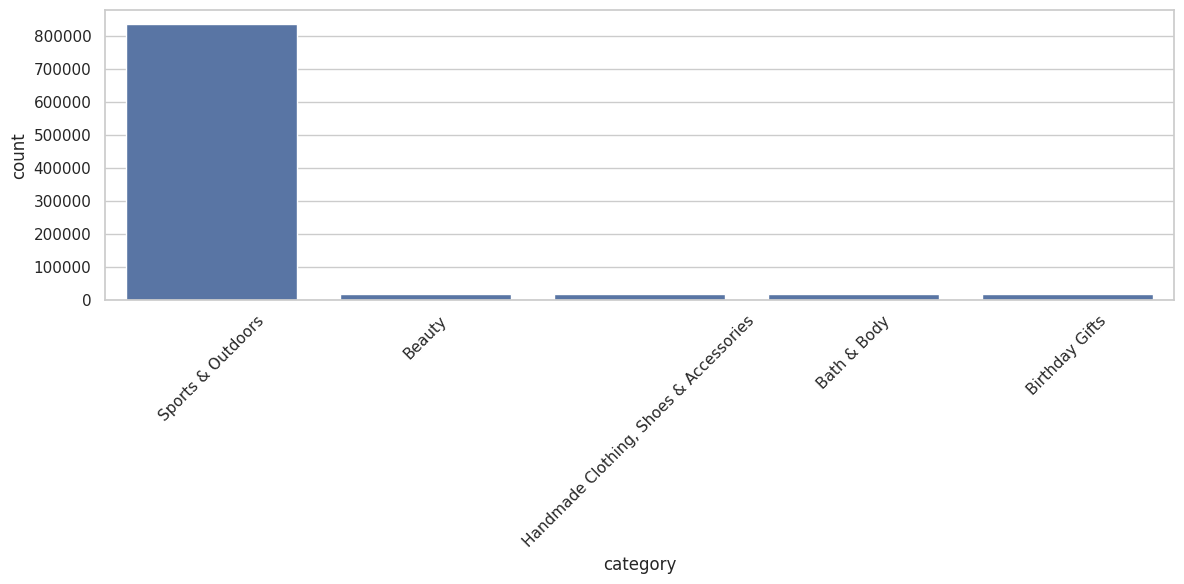

In [ ]:
sns.barplot(freq_cat_top5)
plt.xticks(rotation=45)  # Rotate x-axis labels
plt.tight_layout()       # Prevent label cutoff
plt.show()

In [ ]:
##### Other options ###
# sns.barplot(
#     x="category",
#     y='count',
#     data=df_freq_cat_top5,
#     # palette='viridis',
#     legend=True,
# )
# plt.xticks(rotation=45)  # Rotate x-axis labels


# sns.barplot(
#     x="count",
#     y='category',
#     data=df_freq_cat_top5,
#     # palette='viridis',
#     legend=True,
# )

## wrong output for countplot!!

# plt.tight_layout()       # Prevent label cutoff
# plt.show()

TypeError: Cannot pass values for both `x` and `y`.

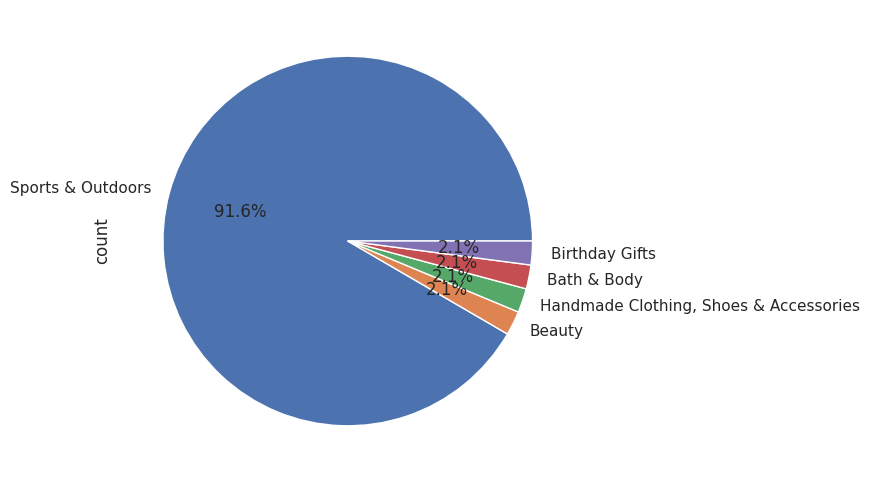

In [82]:
freq_cat_top5.plot(
    kind='pie', autopct='%1.1f%%'
)
plt.show()

**Insights**  
1. Based on the bar plot we can say that the most popular product on Amazon UK is: Sports and Outdoors.
2. It represents a proportion of 34% of the products in the dataset
3. Based on the pie plot we confirm that Sports and Outdoors is the most populat product on Amazon UK and represents ~92% of the first 5 top ordered products



### Part 2: Delving into Product Pricing

**Business Question**: How are products priced on Amazon UK, and are there specific price points or ranges that are more common?

1. **Measures of Centrality**:
    - Calculate the mean, median, and mode for the `price` of products.
    - What's the average price point of products listed? How does this compare with the most common price point (mode)?



In [86]:
### Measure the centrality ###
avg_price = float(aws_products['price'].mean())
median_price = float(aws_products['price'].median())
mode_price = float(aws_products['price'].mode())

print('The average price of the products is {:.2f}'.format(avg_price)) ##round(avg_price,2)
print('The median price of the products is {:.2f}'.format(median_price)) ##round(avg_price,2)
print('The mode price of the products is {:.2f}'.format(mode_price)) ##round(avg_price,2)
# print(round(median_price,2))
# print(round(mode_price,2))


The average price of the products is 89.24
The median price of the products is 19.09
The mode price of the products is 9.99


**Insights** from the centrality Statistics on 'price', we can conclude that:

1. The average price of the products in the dataset is approximately `89.24`pounds.
2. The average price (`89.24`) is much higher and represents almost 9 times the mode price (`9.99`)
3. The median price stands at `19.09`. As the median is lower than the mean, we have a skew in the distribution of prices towards higher values.


2. **Measures of Dispersion**:
    - Determine the variance, standard deviation, range, and interquartile range for product `price`.
    - How varied are the product prices? Are there any indicators of a significant spread in prices?

In [119]:
### Measure the dispersion ###
std_price = float(aws_products['price'].std())
var_price = float(aws_products['price'].var())
range_price = float(aws_products['price'].max() - aws_products['price'].min())

Q1 = aws_products['price'].quantile(0.25)
Q3 = aws_products['price'].quantile(0.75)
IQR = float(Q3 - Q1)

print('The variance and std in the price values are respectively {:.2f} and {:.2f}'.format(var_price, std_price))
print('The range of price values is approximately {:.2f} standing between {:.2f} and {:.2f}'.format(range_price, aws_products['price'].min(),aws_products['price'].max()))
print('The interquartile range (IQR), is between {:.2f} and {:.2f} with a value of {:.2f}.'.format(Q1, Q3,  IQR))


# print(round(std_price,2))
# print(round(var_price, 2))
# print(round(range_price, 2))
# print(round(IQR, 2))


The variance and std in the price values are respectively 119445.49 and 345.61
The range of price values is approximately 100000.00 standing between 0.00 and 100000.00
The interquartile range (IQR), is between 9.99 and 45.99 with a value of 36.00.


In [ ]:
CV = round(float(num.price.std()/num.price.mean()), 2) ##>>> coefficeint of variation
print(CV)

# ## <10 close: around the average 
# ## 10-30: moderate dispersion

# ##>30 big disprsion dispersion

3.87


**Insights** from Summary Statistics for 'price':

1. The range in prices is approximately `100000.0`, highlighting a wide range of values in the dataset.

2. Even with a high range of values the standard deviation is approximately `345.61`. This indicates that sale prices have a low dispersion from the average. This is confirmed with a CV value of `3.87%` < `10%`

3. The interquartile range (IQR) is between `9.99` and `45.99`. This means that 50% of the products in the dataset were sold with `36` pounds.

3. **Visualizations**:
    - Is there a specific price range where most products fall? Plot a histogram to visualize the distribution of product prices. *If its hard to read these diagrams, think why this is, and explain how it could be solved.*.
    - Are there products that are priced significantly higher than the rest? Use a box plot to showcase the spread and potential outliers in product pricing. 

---

In [ ]:
sns.histplot(aws_products.price, bins= 'auto', ax=axes[0], legend=True)

In [141]:
aws_products.price.unique()

array([ 21.99,  23.99,  31.99, ..., 358.42, 341.67, 317.34],
      shape=(82916,))

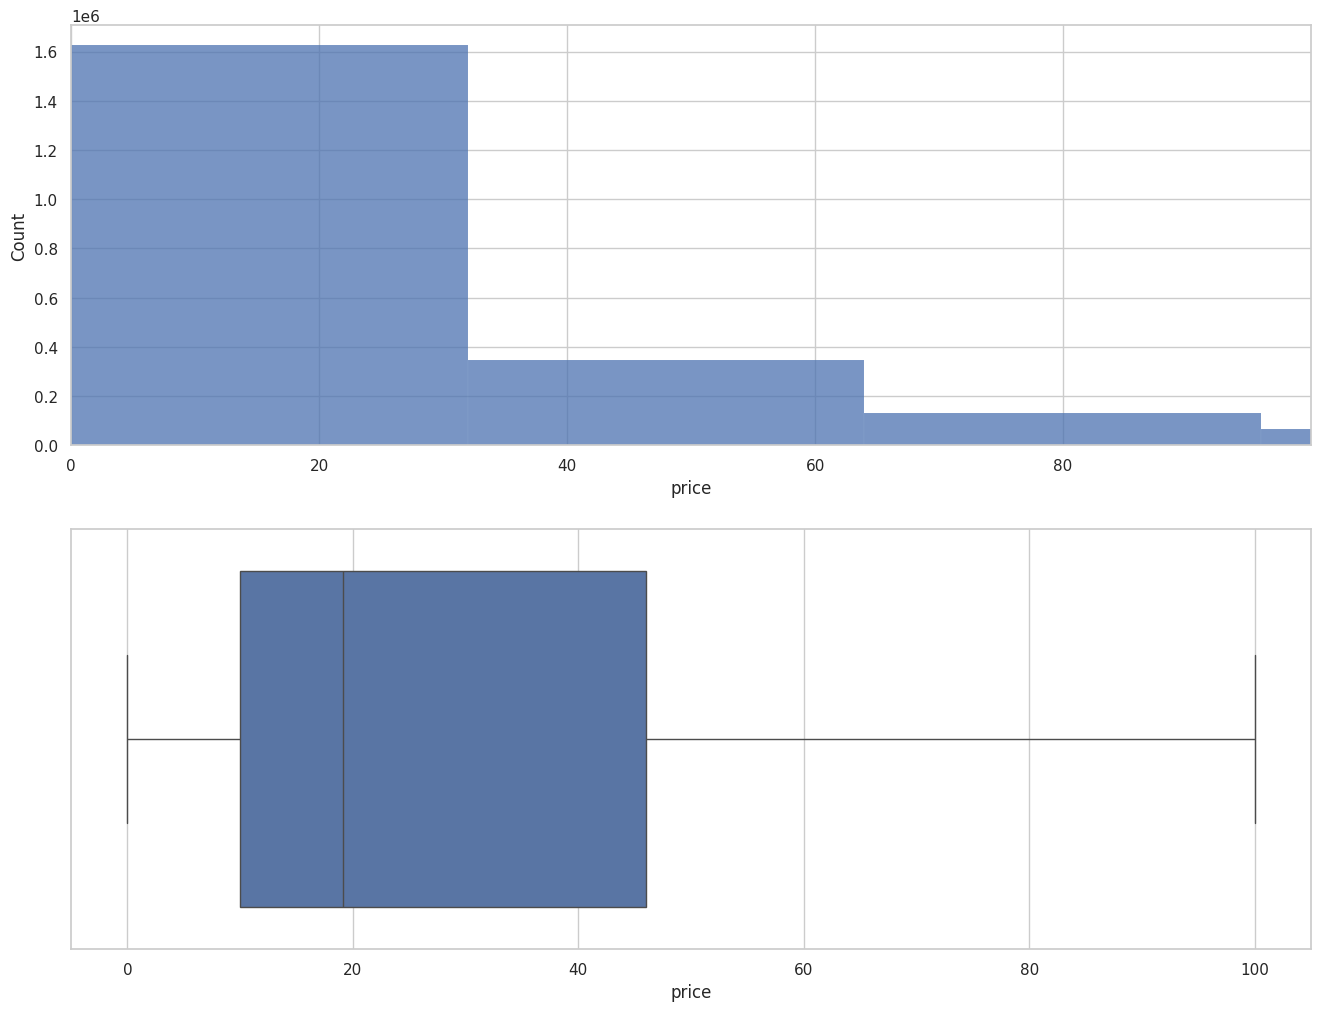

In [140]:
### Visualizstion ###
fig, axes = plt.subplots(2, 1, figsize=(16, 12))

sns.histplot(aws_products.price, bins= 'auto', ax=axes[0], legend=True)

### The problem with the histogram is that it very affected with the maximum value which is an extreme value considering 
# the average pattern of the price values >> Solution for visualization might be to limit limit the x_axis range to a max_value
# example >> Qu75 + 1.5*IQR
max_x = Q3 + 1.5 * IQR
min_x = Q1 - 1.5 * IQR
axes[0].set_xlim(max(aws_products['price'].min(), min_x), min(aws_products['price'].max(), max_x))  # Limit x-axis

# aws_products['price'].plot(
#     kind='box', ax=axes[1], 
# )

sns.boxplot(x="price", data=aws_products, ax=axes[1], showfliers=False, legend=True)

plt.show()

**Insights** from visualizations of 'price', we note that:
1. There are extreme values which are affecting the overall distribution
2. Most of the price values are under `100` and particulary under `45.99`


### Part 3: Unpacking Product Ratings

**Business Question**: How do customers rate products on Amazon UK, and are there any patterns or tendencies in the ratings?

1. **Measures of Centrality**:
    - Calculate the mean, median, and mode for the `rating` of products.
    - How do customers generally rate products? Is there a common trend?

In [123]:
aws_products.columns

Index(['uid', 'asin', 'title', 'stars', 'reviews', 'price', 'isBestSeller',
       'boughtInLastMonth', 'category'],
      dtype='object')

In [125]:
num.describe()

,uid,stars,reviews,price,boughtInLastMonth
count,2.443651e+06,2.443651e+06,2.443651e+06,2.443651e+06,2.443651e+06
mean,1.370545e+06,2.152836e+00,4.806278e+02,8.924381e+01,2.589699e+01
std,8.160562e+05,2.194865e+00,5.944124e+03,3.456089e+02,2.404837e+02
min,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,6.589215e+05,0.000000e+00,0.000000e+00,9.990000e+00,0.000000e+00
50%,1.349029e+06,0.000000e+00,0.000000e+00,1.909000e+01,0.000000e+00
75%,2.060686e+06,4.400000e+00,5.900000e+01,4.599000e+01,0.000000e+00
max,2.828593e+06,5.000000e+00,1.356658e+06,1.000000e+05,5.000000e+04


In [112]:
### Measure the centrality ###
avg_rating = float(aws_products['stars'].mean())
median_rating = float(aws_products['stars'].median())
mode_rating = float(aws_products['stars'].mode())

print('The average rating value of the products is {:.2f}'.format(avg_rating))
print('The median rating value of the products is {:.2f}'.format(median_rating)) 
print('The mode rating value of the products is {:.2f}'.format(mode_rating))

# print(avg_rating)
# print(median_rating)
# print(mode_rating)

The average rating value of the products is 2.15
The median rating value of the products is 0.00
The mode rating value of the products is 0.00


In [128]:
aws_products['stars'].unique()

array([4.7, 4.6, 4.5, 4.8, 0. , 4.4, 4.3, 4.1, 4.9, 5. , 3.8, 3.6, 4. ,
       4.2, 3. , 3.9, 2.5, 3.4, 3.7, 3.2, 3.3, 3.5, 2.7, 2.1, 1. , 3.1,
       2. , 2.9, 2.8, 1.5, 2.2, 2.3, 2.6, 2.4, 1.4, 1.9, 1.8, 1.7, 1.6,
       1.2, 1.3, 1.1])

**Insights** from the centrality Statistics on 'stars', we can conclude that:

1. The average rating of the products in the dataset is approximately `2.15`.
2. The average rating value (`2.15`) is higher than the mode and median values (`0.00`)
3. The median price stands at `0.00`. As the median is lower than the mean, we have a skew in the distribution of prices towards higher values: Positive skew distribution
3. The customers tend to give a rate of `0.00`.


2. **Measures of Dispersion**:
    - Determine the variance, standard deviation, and interquartile range for product `rating`.
    - Are the ratings consistent, or is there a wide variation in customer feedback?

In [ ]:
## Measures of Dispersion##

std_rating = float(aws_products['stars'].std())
var_rating = float(aws_products['stars'].var())

max_rating = aws_products['stars'].max()
min_rating = aws_products['stars'].min()
range_rating = float(max_rating - min_rating)

Q1_rating = aws_products['stars'].quantile(0.25)
Q3_rating = aws_products['stars'].quantile(0.75)
IQR_rating = float(Q3_rating - Q1_rating)


print('The variance and std in the ratings values are respectively {:.2f} and {:.2f}'.format(var_rating, std_rating))
print('The range of the ratings values is approximately {:.2f} standing between {:.2f} and {:.2f}'.format(range_rating, min_rating, max_rating))
print('The interquartile range (IQR), is between {:.2f} and {:.2f} with a value of {:.2f}.'.format(Q1_rating, Q3_rating, IQR_rating))

# print(round(std_rating, 2))
# print(round(var_rating,2))
# print(round(range_rating,2))
# print(round(IQR_rating, 2))

The variance and std in the price values are respectively 4.82 and 2.19
The range of price values is approximately 5.00 standing between 0.00 and 5.00
The interquartile range (IQR), is between 0.00 and 4.40 with a value of 4.40.


In [117]:
CV_rating = std_rating / avg_rating
CV_rating

1.0195225722320886

-- Insights
- Are the ratings consistent, or is there a wide variation in customer feedback?

**Insights** from Summary Statistics for 'rating':

1. The range in rating values is approximately `5.00`, highlighting a wide range of values in the dataset from 0.00 to 5.00.

2. The standard deviation is approximately `2.19`. This indicates that sale prices have a low dispersion from the average. This is confirmed with a CV value of `1.02%` < `10%`. The ratings are consitent and close to the average.

3. The interquartile range (IQR) is between `0.00` and `4.40`. This means that 50% of the products in the dataset were rated with `4.40`.

3. **Shape of the Distribution**:
    - Calculate the skewness and kurtosis for the `rating` column. 
    - Are the ratings normally distributed, or do they lean towards higher or lower values?


In [120]:
## Shape of the Distribution ##

skewness_rating = round(float(aws_products['stars'].skew()), 2)
kurtosis_rating = round(float(aws_products['stars'].kurtosis()), 2)

print('The skewness of the rating values is {:.2f}'.format(skewness_rating))
print('The kurtosis of the rating values is {:.2f}'.format(kurtosis_rating))

# print(skewness_rating)
# print(kurtosis_rating)

The skewness of the rating values is 0.08
The kurtosis of the rating values is -1.93


- **Skewness = 0:**  
     The distribution is perfectly symmetrical, resembling a normal distribution.
- **Skewness > 0:**  
     The distribution is **positively skewed** (right-skewed).  
     - Longer tail on the **right** side.  
     - The bulk of the data is concentrated on the **left**.
- **Skewness < 0:**  
     The distribution is **negatively skewed** (left-skewed).  
     - Longer tail on the **left** side.  
     - The bulk of the data is concentrated on the **right**.

**Insights** from the centrality Statistics on 'rating', we can conclude that:

1. The rating values are not normally distributed because the avg != median and the mode.
3. The skewness in the ratings values is `0.08` slightly above zero. We conform here a slight skew in the distribution of rating values towards higher values: Positive skew distribution


4. **Visualizations**:
    - Plot a histogram to visualize the distribution of product ratings. Is there a specific rating that is more common?

---

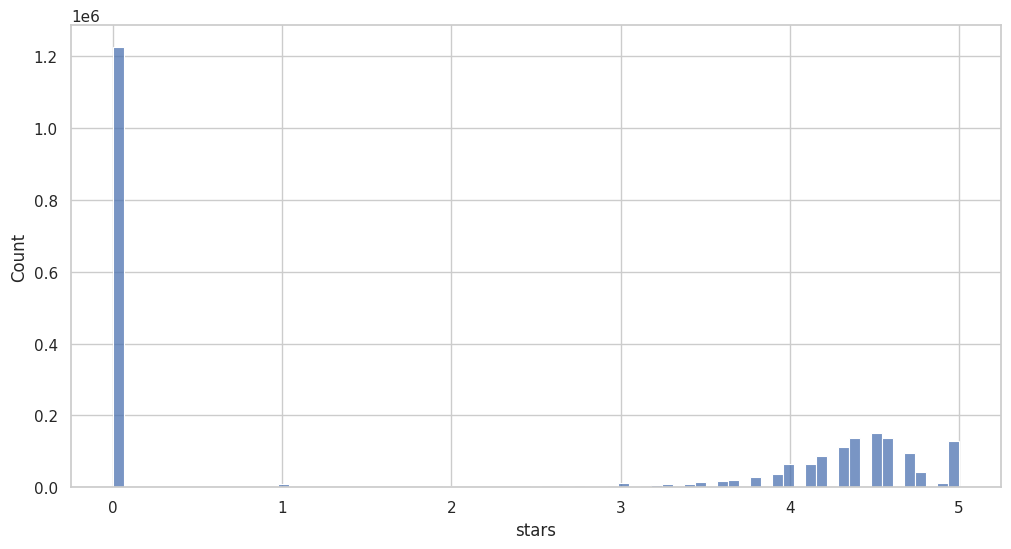

In [127]:
## Viz ##
# aws_products['stars'].hist()

sns.histplot(aws_products.stars, bins="auto") ##, kde=True
plt.show()


In [139]:
aws_products

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers
...,...,...,...,...,...,...,...,...,...
2443646,2828589,B0CHSD7P2Q,"Motorbike Armour, Motorbike Clothing, Cycling ...",0.0,0,22.34,False,0,Motorbike Clothing
2443647,2828590,B0B7B8FNBQ,PROFIRST Waterproof Motorcycle 2 Piece Ladies ...,0.0,0,97.99,False,0,Motorbike Clothing
2443648,2828591,B0BD5FL5FB,Men’s Motorcycle Motorbike Biker Trousers Kevl...,0.0,0,52.99,False,0,Motorbike Clothing
2443649,2828592,B008OYLL4I,Texpeed Mens Motorcycle Motorbike Biker Trouse...,4.3,404,79.99,False,0,Motorbike Clothing


**Insights** 
1. The most common rating value is 0.00
